# Clustering Track — NCR Ride Segmentation
### 23CSE301 Machine Learning — Capstone, Review 2 · Team 6 · *Gig Analytics Earnings*

**Team 6:** Harsha Vardhan · M Pranav · S Rahul Kumar

**Dataset:** NCR Ride Bookings (Kaggle) — cleaned 10,000-row sample of completed rides
**Goal:** group rides into natural segments *without labels*, using trip and service-quality features
**Algorithms (guideline 3.3):** K-Means (elbow curve) · Agglomerative Hierarchical (dendrogram, linkage comparison)
**Metrics (all mandatory):** Silhouette Score (↑), Davies-Bouldin Index (↓), Calinski-Harabasz Index (↑) · PCA 2-D plots for every algorithm · t-SNE

| Section | Content |
|---|---|
| A | Dataset audit & EDA |
| B | Preprocessing (feature choice, log transform, scaling) |
| C | K-Means — elbow curve, choosing *k*, fit, metrics |
| D | Agglomerative clustering — dendrogram, linkage comparison, metrics |
| E | Comparison table, PCA & t-SNE visualisation, cluster profiles |
| F | Post-hoc check against known labels & conclusion |

> Ground-truth style columns (`Vehicle Type`, `Payment Method`) are **never used for fitting**; they are only used afterwards to interpret the clusters (guideline 3.3).

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 140)
RANDOM_STATE = 42
palette = sns.color_palette("colorblind")
os.makedirs('figures', exist_ok=True)
os.makedirs('../models', exist_ok=True)

_fig_no = [0]
_orig_show = plt.show
def _show_and_save(*a, **k):
    for n in plt.get_fignums():
        _fig_no[0] += 1
        plt.figure(n).savefig(f'figures/clu_{_fig_no[0]:02d}.png', dpi=110, bbox_inches='tight')
    _orig_show(*a, **k)
plt.show = _show_and_save

## Section A — Dataset Audit & EDA

In [2]:
raw = pd.read_csv('../data/ncr_clustering_10k.csv')
print("Shape:", raw.shape)
display(raw.head())
display(raw.dtypes.to_frame('dtype').T)
print("Missing values:", raw.isna().sum().sum(), "| Duplicate rows:", raw.duplicated().sum())
display(raw.describe().T.round(2))

Shape: (10000, 8)


,Vehicle Type,Booking Value,Ride Distance,Avg VTAT,Avg CTAT,Driver Ratings,Customer Rating,Payment Method
0,Go Mini,106.0,23.43,7.0,43.0,3.6,4.6,Cash
1,Go Sedan,173.0,11.91,7.4,39.1,4.2,4.9,Uber Wallet
2,Go Sedan,565.0,32.22,6.3,16.2,4.4,3.9,UPI
3,Bike,763.0,5.03,9.0,42.9,4.9,4.4,UPI
4,Auto,461.0,17.87,9.5,15.4,3.7,4.3,UPI


,Vehicle Type,Booking Value,Ride Distance,Avg VTAT,Avg CTAT,Driver Ratings,Customer Rating,Payment Method
dtype,str,float64,float64,float64,float64,float64,float64,str


Missing values: 0 | Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Booking Value,10000.0,505.44,393.98,50.0,230.00,410.00,687.00,4228.00
Ride Distance,10000.0,26.15,13.84,2.0,14.34,26.11,38.07,49.99
Avg VTAT,10000.0,8.54,3.75,2.0,5.30,8.50,11.80,15.00
Avg CTAT,10000.0,30.16,8.73,15.0,22.60,30.20,37.80,45.00
Driver Ratings,10000.0,4.23,0.44,3.0,4.10,4.30,4.60,5.00
Customer Rating,10000.0,4.41,0.44,3.0,4.20,4.40,4.80,5.00


| Column | Meaning | Used for clustering? |
|---|---|---|
| `Booking Value` | Fare paid (₹) | ✔ (log-transformed) |
| `Ride Distance` | Trip length (km) | ✔ |
| `Avg VTAT` | Avg vehicle time-to-arrive at pickup (min) | ✔ |
| `Avg CTAT` | Avg customer time-to-arrive / trip time (min) | ✔ |
| `Driver Ratings` | Rating given to the driver | ✔ |
| `Customer Rating` | Rating given to the customer | ✔ |
| `Vehicle Type` | Service class | ✘ — kept aside for post-hoc interpretation |
| `Payment Method` | UPI / Cash / … | ✘ — kept aside for post-hoc interpretation |

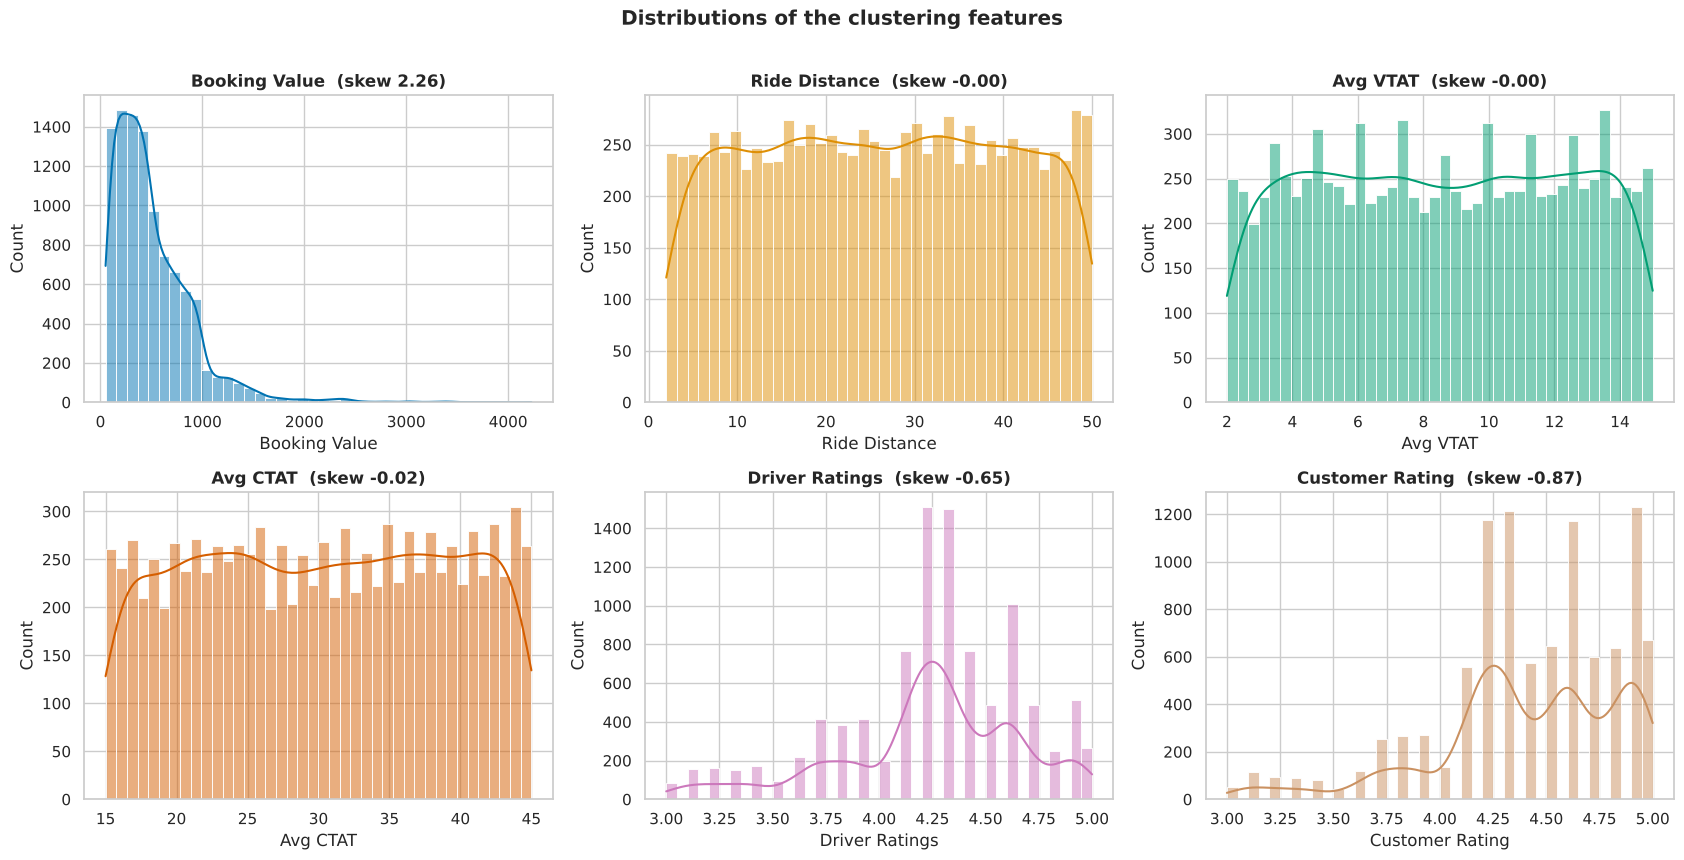

In [3]:
NUM = ['Booking Value', 'Ride Distance', 'Avg VTAT', 'Avg CTAT', 'Driver Ratings', 'Customer Rating']
fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))
for ax, col, c in zip(axes.ravel(), NUM, palette):
    sns.histplot(raw[col], bins=40, kde=True, color=c, ax=ax)
    ax.set_title(f"{col}  (skew {raw[col].skew():.2f})", fontweight='bold')
plt.suptitle('Distributions of the clustering features', fontweight='bold', y=1.01)
plt.tight_layout(); plt.show(); plt.close('all')

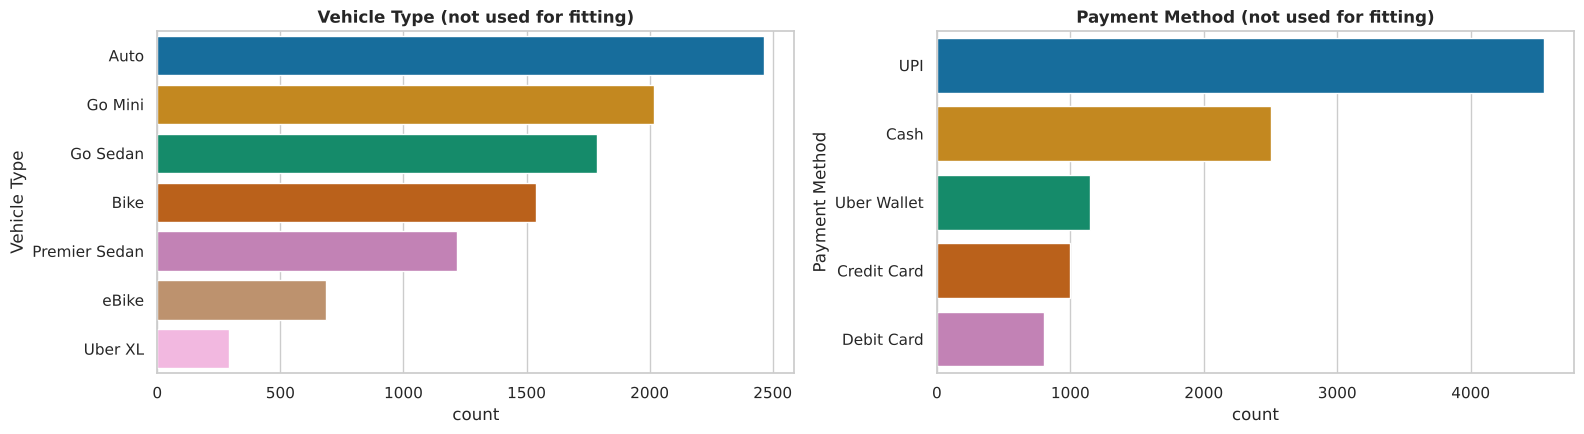

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sns.countplot(data=raw, y='Vehicle Type', order=raw['Vehicle Type'].value_counts().index, palette=palette, ax=axes[0])
axes[0].set_title('Vehicle Type (not used for fitting)', fontweight='bold')
sns.countplot(data=raw, y='Payment Method', order=raw['Payment Method'].value_counts().index, palette=palette, ax=axes[1])
axes[1].set_title('Payment Method (not used for fitting)', fontweight='bold')
plt.tight_layout(); plt.show(); plt.close('all')

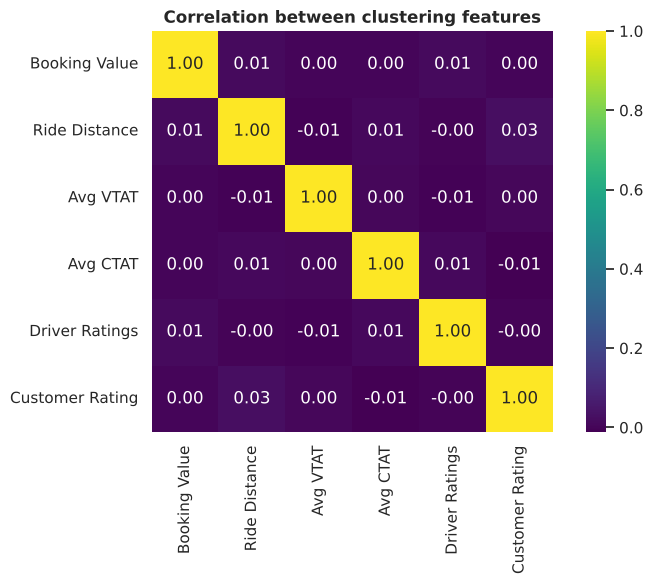

Largest |off-diagonal correlation|: 0.026


In [5]:
plt.figure(figsize=(8, 6))
sns.heatmap(raw[NUM].corr(), annot=True, fmt='.2f', cmap='viridis', square=True)
plt.title('Correlation between clustering features', fontweight='bold'); plt.tight_layout(); plt.show(); plt.close('all')
print("Largest |off-diagonal correlation|: %.3f" % (raw[NUM].corr().abs().values[~np.eye(len(NUM), dtype=bool)].max()))

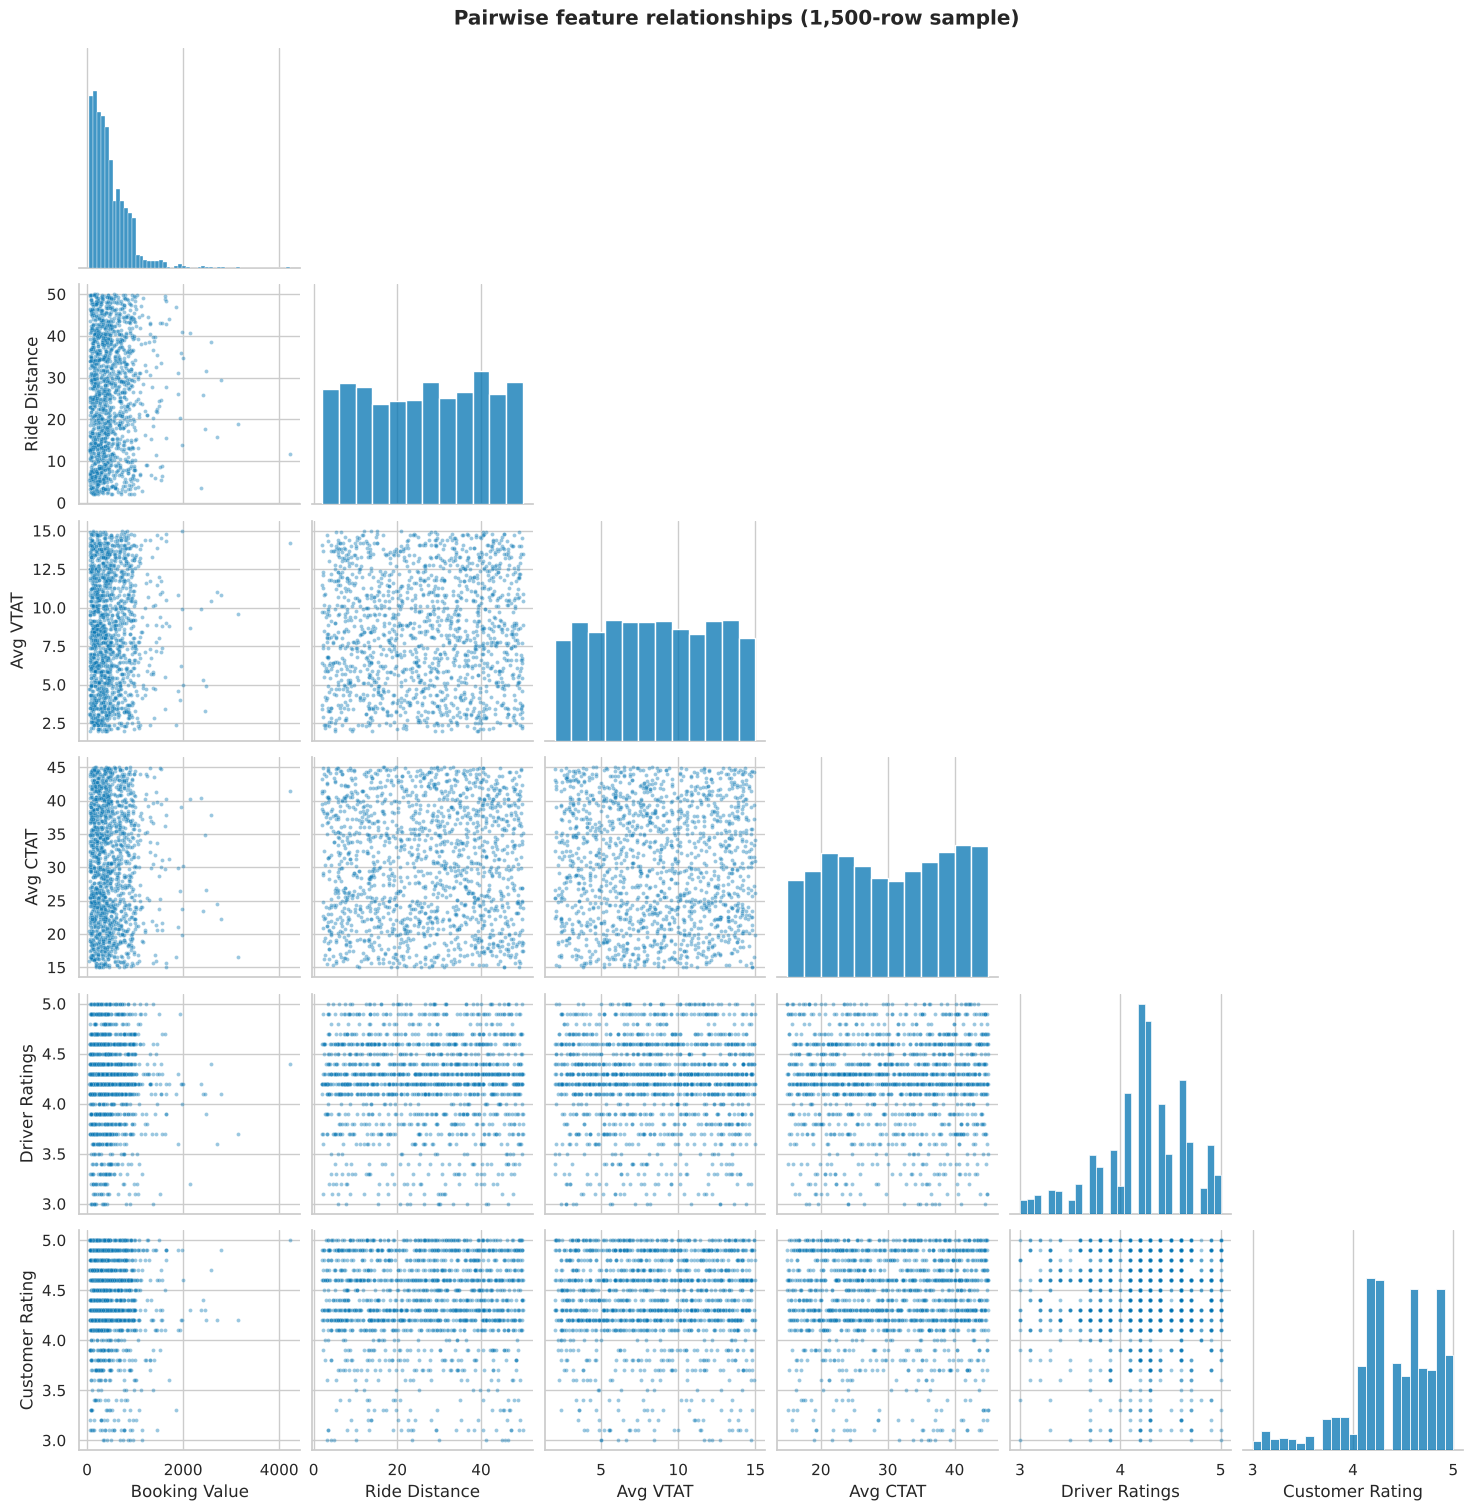

In [6]:
sns.pairplot(raw[NUM].sample(1500, random_state=RANDOM_STATE), corner=True, plot_kws={'s': 8, 'alpha': .4, 'color': palette[0]}, diag_kws={'color': palette[0]})
plt.suptitle('Pairwise feature relationships (1,500-row sample)', fontweight='bold', y=1.01)
plt.show(); plt.close('all')

**EDA takeaways.** No missing values. `Booking Value` is strongly right-skewed (long tail of expensive rides), so it is log-transformed before clustering. 
The other features are bounded and roughly symmetric, and the features are nearly uncorrelated — so there is no single dominant axis, and any cluster structure has to come from combinations of features.

## Section B — Preprocessing

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

prep = ColumnTransformer([
    ('log_scale', Pipeline([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')), ('sc', StandardScaler())]), ['Booking Value']),
    ('scale', StandardScaler(), [c for c in NUM if c != 'Booking Value']),
])
X = prep.fit_transform(raw[NUM])
FEATS = [f.split('__')[1] for f in prep.get_feature_names_out()]
print("Model matrix:", X.shape)
display(pd.DataFrame(X, columns=FEATS).describe().T[['mean', 'std', 'min', 'max']].round(3))

Model matrix: (10000, 6)


,mean,std,min,max
Booking Value,-0.0,1.0,-2.594,3.084
Ride Distance,-0.0,1.0,-1.745,1.723
Avg VTAT,-0.0,1.0,-1.741,1.721
Avg CTAT,-0.0,1.0,-1.737,1.701
Driver Ratings,0.0,1.0,-2.808,1.756
Customer Rating,-0.0,1.0,-3.214,1.361


**Why these steps**
- **Scaling is essential**: K-Means and Agglomerative clustering use Euclidean distance, so without scaling `Booking Value` (hundreds) would completely dominate ratings (3–5).
- **`log1p` on `Booking Value`** reduces the influence of a few very expensive rides that would otherwise form their own tiny clusters.
- **Categoricals are excluded** from the distance: one-hot columns would create artificial, equally spaced "clusters" per category, and we want to *discover* whether segments line up with vehicle types, not force it.
- *Leakage note:* clustering is unsupervised and has no train/test split, so fitting the scaler on all rows is correct here (guideline 7.1 applies to supervised tracks).

## Section C — Algorithm 1: K-Means Clustering

K-Means places *k* centroids and alternates between (1) assigning each ride to its nearest centroid and (2) moving each centroid to the mean of its rides, minimising the **within-cluster sum of squares (inertia)**. `n_init=10` restarts guard against bad initialisations.

In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

ks = range(2, 11)
rows = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    rows.append({'k': k, 'Inertia': km.inertia_, 'Silhouette': silhouette_score(X, km.labels_),
                 'Davies-Bouldin': davies_bouldin_score(X, km.labels_), 'Calinski-Harabasz': calinski_harabasz_score(X, km.labels_)})
k_df = pd.DataFrame(rows)
display(k_df.round(4))

,k,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,52447.8931,0.1283,2.5391,1439.6696
1,3,47544.6991,0.1293,2.2218,1309.4695
2,4,43459.3990,0.1334,2.0019,1268.1729
3,5,40065.7700,0.1303,1.8395,1243.2375
4,6,37165.9175,0.1309,1.6889,1228.0375
5,7,34841.4770,0.1329,1.6119,1202.6432
6,8,33249.4633,0.1290,1.5638,1148.4283
7,9,31877.8545,0.1294,1.5179,1101.7430
8,10,30667.9654,0.1364,1.4705,1061.6507


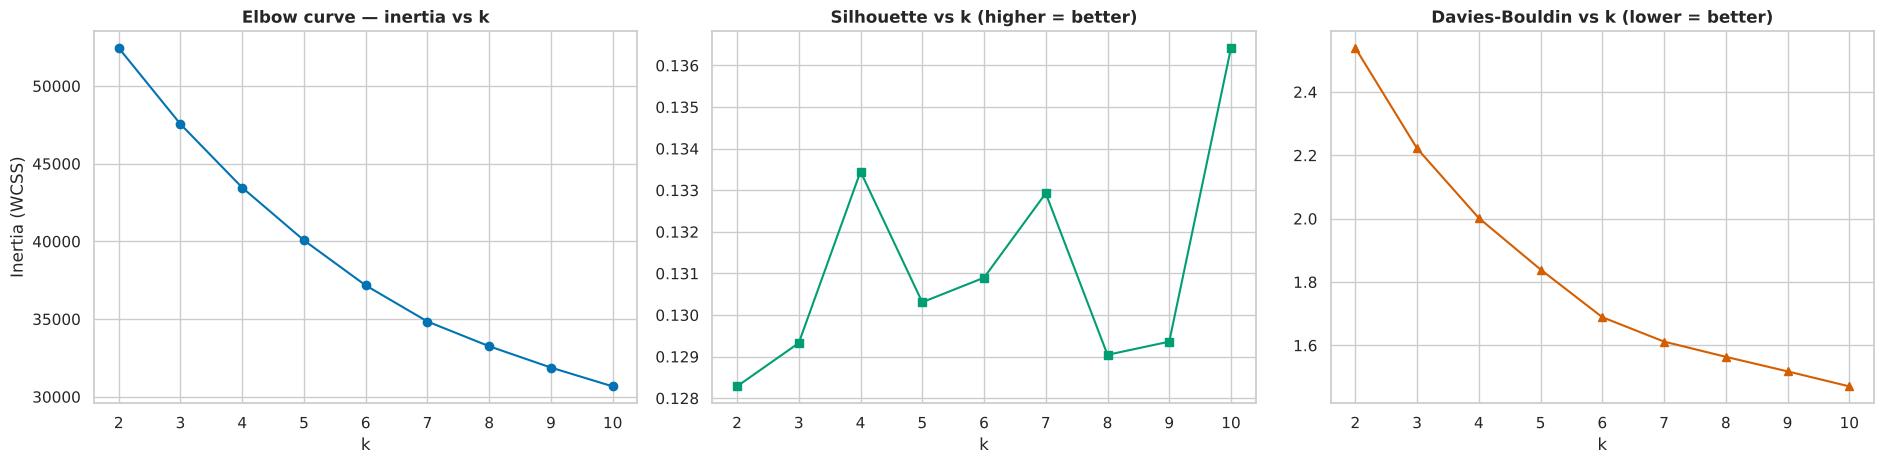

Elbow (max curvature) suggests k = 3;  best silhouette at k = 10


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
axes[0].plot(k_df['k'], k_df['Inertia'], 'o-', color=palette[0]); axes[0].set_title('Elbow curve — inertia vs k', fontweight='bold'); axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia (WCSS)')
axes[1].plot(k_df['k'], k_df['Silhouette'], 's-', color=palette[2]); axes[1].set_title('Silhouette vs k (higher = better)', fontweight='bold'); axes[1].set_xlabel('k')
axes[2].plot(k_df['k'], k_df['Davies-Bouldin'], '^-', color=palette[3]); axes[2].set_title('Davies-Bouldin vs k (lower = better)', fontweight='bold'); axes[2].set_xlabel('k')
plt.tight_layout(); plt.show(); plt.close('all')

# second differences of inertia: the largest positive one marks the sharpest bend ("elbow")
d2 = np.diff(k_df['Inertia'].values, 2)
elbow_k = int(k_df['k'].iloc[1 + int(np.argmax(d2))])
sil_k = int(k_df.loc[k_df['Silhouette'].idxmax(), 'k'])
print(f"Elbow (max curvature) suggests k = {elbow_k};  best silhouette at k = {sil_k}")

In [10]:
# Decision rule (declared in advance):
#   * if the silhouette curve is informative (varies by >= 0.02 across k), take the silhouette-best k;
#   * if it is essentially flat, silhouette cannot discriminate between k values, so the elbow decides.
sil_range = k_df['Silhouette'].max() - k_df['Silhouette'].min()
K = sil_k if sil_range >= 0.02 else elbow_k
print(f"Silhouette varies by only {sil_range:.4f} across k = 2..10 -> {'informative' if sil_range >= 0.02 else 'flat, so the elbow decides'}")
print(f"Chosen number of clusters K = {K}  (used for BOTH algorithms so the comparison is fair)")

Silhouette varies by only 0.0081 across k = 2..10 -> flat, so the elbow decides
Chosen number of clusters K = 3  (used for BOTH algorithms so the comparison is fair)


**Choosing *k*.** The inertia curve always decreases as *k* grows, so the elbow is read where the decrease *slows down most* (largest second difference). The silhouette curve measures separation directly — but when it is almost flat across all *k*, picking its maximum would just reward noise (and often the edge of the search range). Hence the rule in the cell above: silhouette decides only if it varies meaningfully; otherwise the elbow decides. The same *K* is used for both algorithms so their metrics are comparable. 
A gentle elbow together with a flat, low silhouette is itself evidence that the rides do not form strongly separated groups.

In [11]:
t0 = time.time()
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X)
km_labels = kmeans.labels_
results = [{'Algorithm': f'K-Means (k={K})', 'Silhouette': silhouette_score(X, km_labels), 'Davies-Bouldin': davies_bouldin_score(X, km_labels),
            'Calinski-Harabasz': calinski_harabasz_score(X, km_labels), 'Fit time (s)': time.time() - t0}]
print(pd.Series(km_labels).value_counts().sort_index().rename('rides per cluster').to_string())
pd.DataFrame(results).round(4)

0    4030
1    1971
2    3999


,Algorithm,Silhouette,Davies-Bouldin,Calinski-Harabasz,Fit time (s)
0,K-Means (k=3),0.1293,2.2218,1309.4695,2.1094


## Section D — Algorithm 2: Agglomerative Hierarchical Clustering

Agglomerative clustering starts with every ride as its own cluster and repeatedly **merges the two closest clusters**. *Closeness* is defined by the **linkage**:
- **Ward** — merge that least increases total within-cluster variance (most similar to K-Means)
- **Complete** — distance between the *farthest* members
- **Average** — mean distance between all members
- **Single** — distance between the *closest* members (prone to "chaining")

The full merge history is drawn as a **dendrogram**; cutting it horizontally gives the clusters.

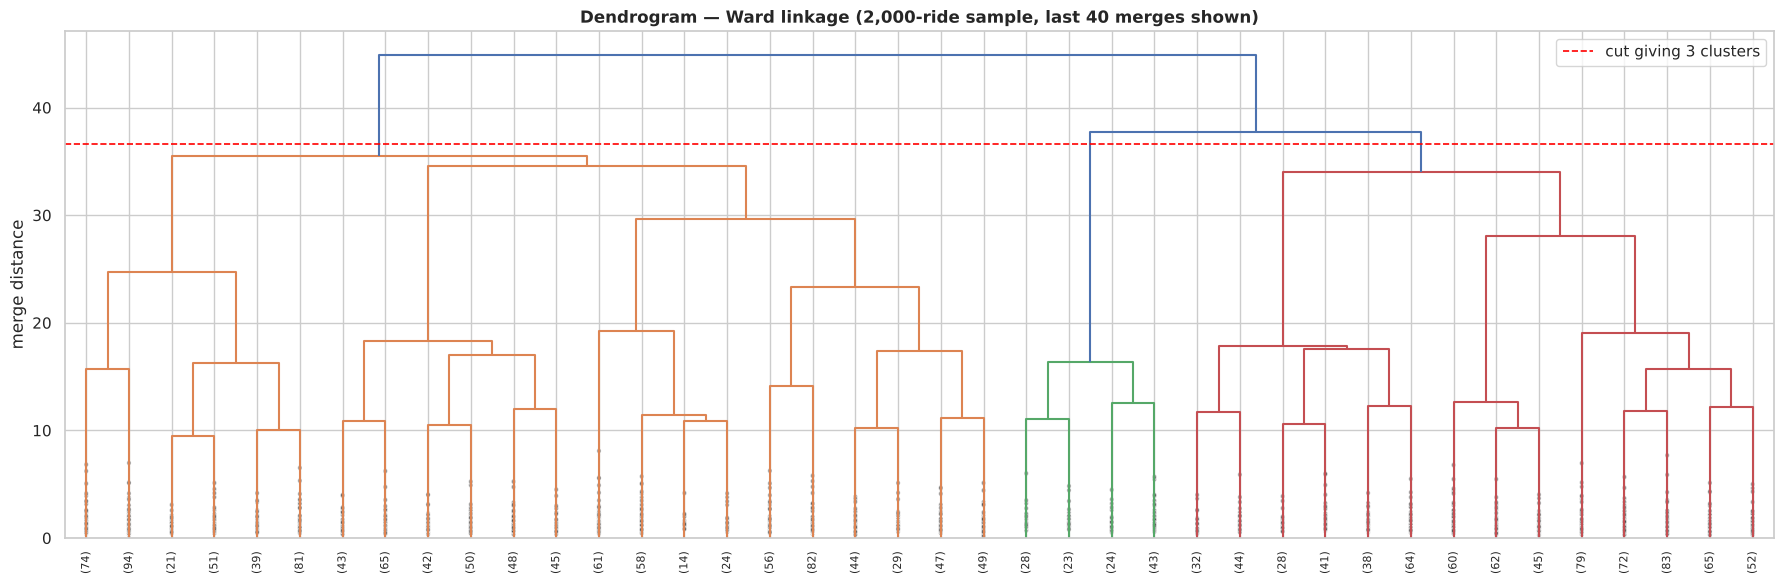

In [12]:
from scipy.cluster.hierarchy import linkage, dendrogram
rng = np.random.RandomState(RANDOM_STATE)
idx = rng.choice(len(X), 2000, replace=False)          # dendrogram on a 2,000-ride sample (readable + fast)
Z = linkage(X[idx], method='ward')
plt.figure(figsize=(18, 6))
dendrogram(Z, truncate_mode='lastp', p=40, leaf_rotation=90, leaf_font_size=8, show_contracted=True, color_threshold=Z[-(K - 1), 2])
cut = (Z[-K, 2] + Z[-(K - 1), 2]) / 2
plt.axhline(cut, color='red', ls='--', lw=1.2, label=f'cut giving {K} clusters')
plt.title('Dendrogram — Ward linkage (2,000-ride sample, last 40 merges shown)', fontweight='bold'); plt.ylabel('merge distance'); plt.legend()
plt.tight_layout(); plt.show(); plt.close('all')

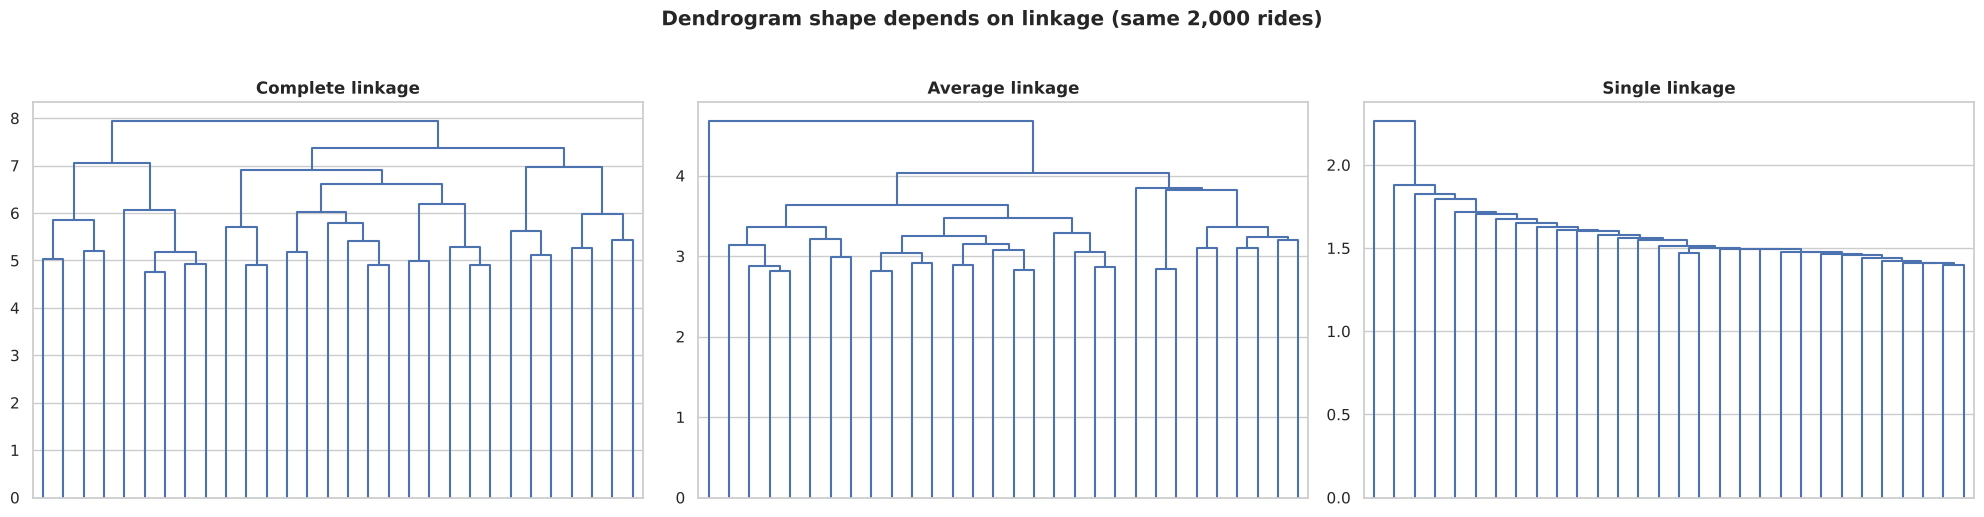

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, method in zip(axes, ['complete', 'average', 'single']):
    dendrogram(linkage(X[idx], method=method), truncate_mode='lastp', p=30, no_labels=True, ax=ax, color_threshold=0)
    ax.set_title(f'{method.title()} linkage', fontweight='bold')
plt.suptitle('Dendrogram shape depends on linkage (same 2,000 rides)', fontweight='bold', y=1.03)
plt.tight_layout(); plt.show(); plt.close('all')

### D2. Linkage comparison (all 10,000 rides, K clusters)

In [14]:
from sklearn.cluster import AgglomerativeClustering
link_rows, agg_labels = [], {}
for method in ['ward', 'complete', 'average', 'single']:
    t0 = time.time()
    lab = AgglomerativeClustering(n_clusters=K, linkage=method).fit_predict(X)
    agg_labels[method] = lab
    sizes = np.bincount(lab)
    link_rows.append({'Linkage': method, 'Silhouette': silhouette_score(X, lab), 'Davies-Bouldin': davies_bouldin_score(X, lab),
                      'Calinski-Harabasz': calinski_harabasz_score(X, lab), 'Smallest cluster': sizes.min(), 'Largest cluster': sizes.max(),
                      'Fit time (s)': time.time() - t0})
link_df = pd.DataFrame(link_rows)
display(link_df.round(4))

,Linkage,Silhouette,Davies-Bouldin,Calinski-Harabasz,Smallest cluster,Largest cluster,Fit time (s)
0,ward,0.0946,2.6132,989.1699,1755,4258,5.5066
1,complete,0.0914,2.5080,837.8653,1521,6565,4.8130
2,average,0.1415,1.0686,15.2285,2,9982,5.3245
3,single,0.2519,0.5309,3.4196,1,9998,2.0763


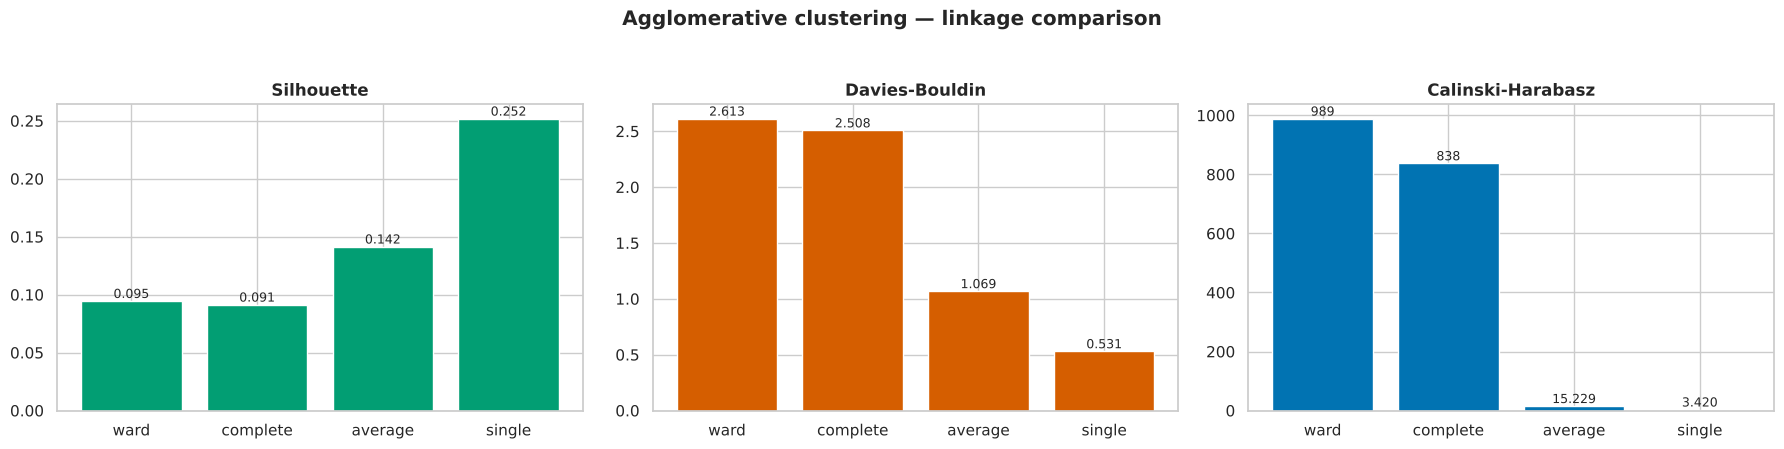

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.3))
for ax, m, c in zip(axes, ['Silhouette', 'Davies-Bouldin', 'Calinski-Harabasz'], [palette[2], palette[3], palette[0]]):
    ax.bar(link_df['Linkage'], link_df[m], color=c); ax.set_title(m, fontweight='bold')
    for i, v in enumerate(link_df[m]): ax.text(i, v, f'{v:.3f}' if v < 100 else f'{v:.0f}', ha='center', va='bottom', fontsize=9)
plt.suptitle('Agglomerative clustering — linkage comparison', fontweight='bold', y=1.04)
plt.tight_layout(); plt.show(); plt.close('all')

**Reading the linkage table.** Silhouette alone can be misleading: *single* (and sometimes *average*) linkage can score a deceptively high silhouette by putting almost every ride in one cluster and leaving a few outliers in tiny clusters — check the *Smallest cluster* column. 
A useful segmentation needs **balanced, interpretable** clusters, so we pick the linkage with the best Calinski-Harabasz score among those whose smallest cluster holds at least 5 % of rides.

In [16]:
valid = link_df[link_df['Smallest cluster'] >= 0.05 * len(X)]
best_link = (valid if len(valid) else link_df).sort_values('Calinski-Harabasz', ascending=False).iloc[0]['Linkage']
agg_lab = agg_labels[best_link]
r = link_df.set_index('Linkage').loc[best_link]
results.append({'Algorithm': f'Agglomerative ({best_link}, k={K})', 'Silhouette': r['Silhouette'], 'Davies-Bouldin': r['Davies-Bouldin'],
                'Calinski-Harabasz': r['Calinski-Harabasz'], 'Fit time (s)': r['Fit time (s)']})
print(f"Selected linkage: {best_link}")
print(pd.Series(agg_lab).value_counts().sort_index().rename('rides per cluster').to_string())

Selected linkage: ward
0    4258
1    1755
2    3987


## Section E — Comparison & Visualisation

### E1. Consolidated metric table

In [17]:
res_df = pd.DataFrame(results)
display(res_df.round(4))
score = (res_df['Silhouette'].rank(ascending=False) + res_df['Davies-Bouldin'].rank(ascending=True) + res_df['Calinski-Harabasz'].rank(ascending=False))
best_algo = res_df.loc[score.idxmin(), 'Algorithm']
wins = {m: res_df.loc[(res_df[m].idxmin() if m == 'Davies-Bouldin' else res_df[m].idxmax()), 'Algorithm'] for m in ['Silhouette', 'Davies-Bouldin', 'Calinski-Harabasz']}
for m, w in wins.items(): print(f"Best on {m:18s}: {w}")
print(f"\nOverall (best average rank across the three metrics): {best_algo}")
from sklearn.metrics import adjusted_rand_score
print(f"Agreement between the two algorithms (Adjusted Rand Index): {adjusted_rand_score(km_labels, agg_lab):.3f}  (1 = identical partitions)")
res_df.round(4).to_csv('../models/clustering_results.csv', index=False)

,Algorithm,Silhouette,Davies-Bouldin,Calinski-Harabasz,Fit time (s)
0,K-Means (k=3),0.1293,2.2218,1309.4695,2.1094
1,"Agglomerative (ward, k=3)",0.0946,2.6132,989.1699,5.5066


Best on Silhouette        : K-Means (k=3)
Best on Davies-Bouldin    : K-Means (k=3)
Best on Calinski-Harabasz : K-Means (k=3)

Overall (best average rank across the three metrics): K-Means (k=3)
Agreement between the two algorithms (Adjusted Rand Index): 0.182  (1 = identical partitions)


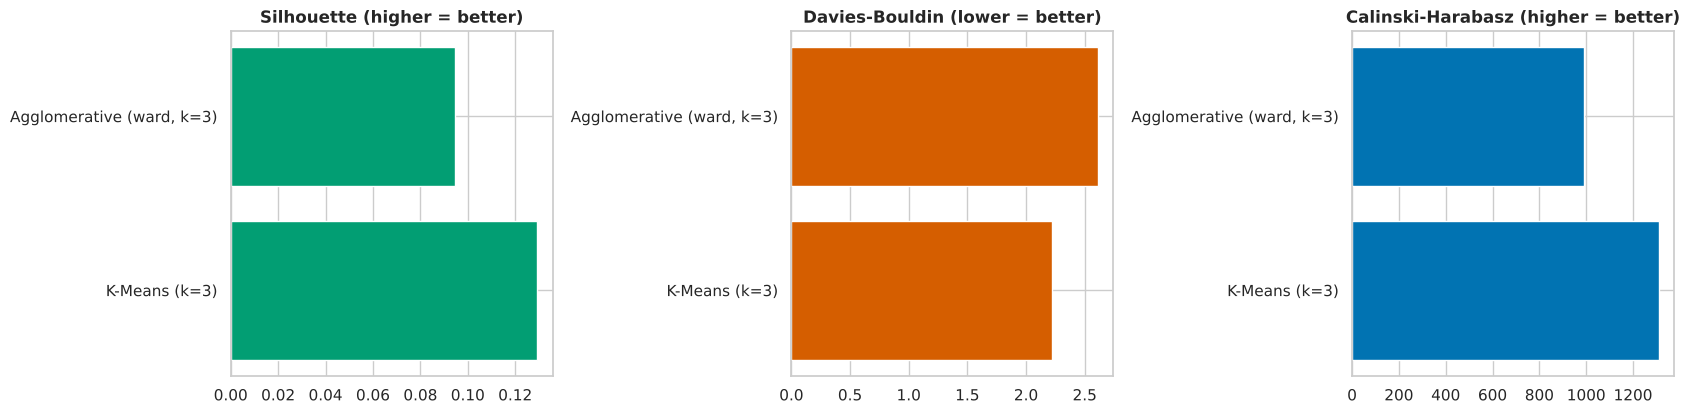

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
for ax, m, c in zip(axes, ['Silhouette', 'Davies-Bouldin', 'Calinski-Harabasz'], [palette[2], palette[3], palette[0]]):
    ax.barh(res_df['Algorithm'], res_df[m], color=c); ax.set_title(m + (' (lower = better)' if m == 'Davies-Bouldin' else ' (higher = better)'), fontweight='bold')
plt.tight_layout(); plt.show(); plt.close('all')

### E2. PCA 2-D projection — every algorithm (mandatory)

Variance explained by PC1 + PC2: 34.1%


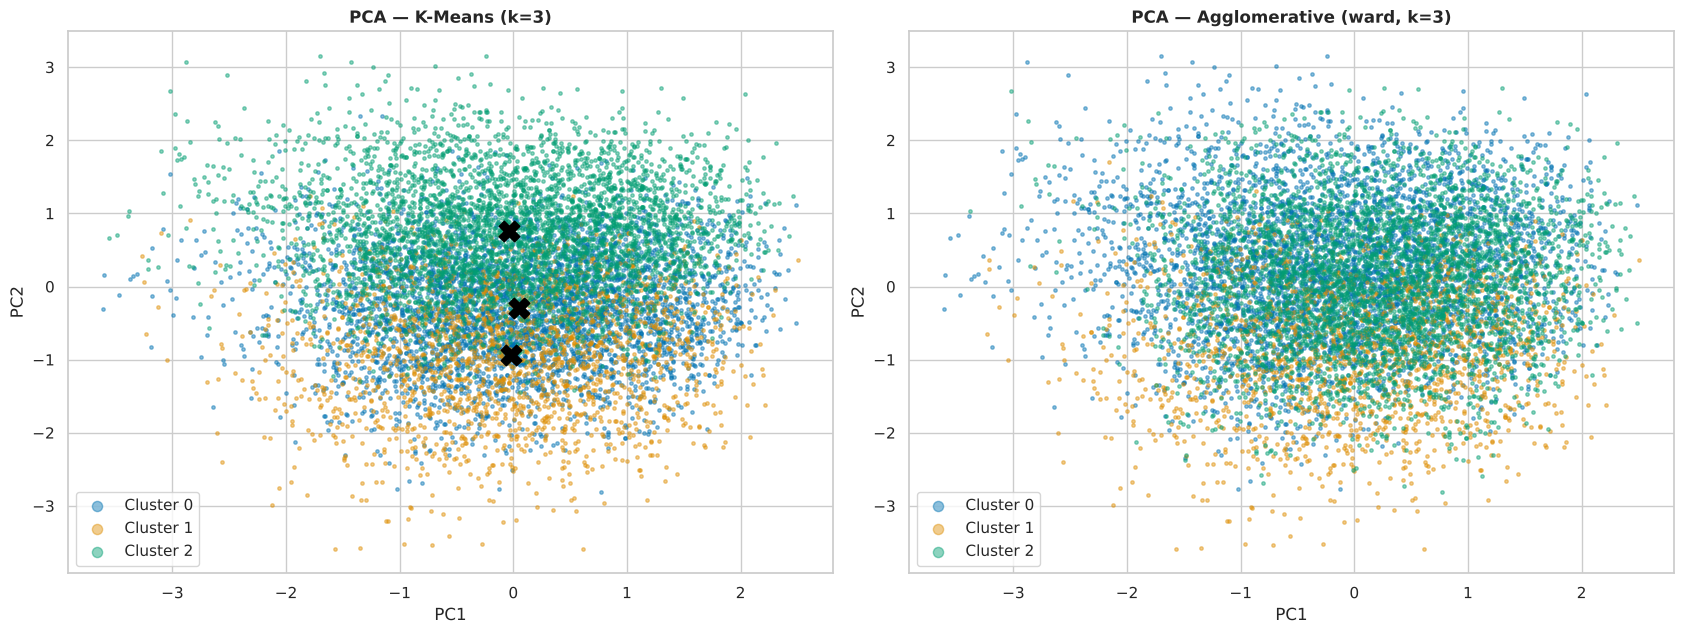

In [19]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X)
P = pca.transform(X)
print("Variance explained by PC1 + PC2: %.1f%%" % (pca.explained_variance_ratio_.sum() * 100))
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, (title, lab) in zip(axes, [(res_df.iloc[0]['Algorithm'], km_labels), (res_df.iloc[1]['Algorithm'], agg_lab)]):
    for c in np.unique(lab):
        ax.scatter(P[lab == c, 0], P[lab == c, 1], s=6, alpha=.45, color=palette[c % 10], label=f'Cluster {c}')
    ax.set_title(f'PCA — {title}', fontweight='bold'); ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.legend(markerscale=3)
cent = pca.transform(kmeans.cluster_centers_)
axes[0].scatter(cent[:, 0], cent[:, 1], marker='X', s=220, c='black', label='centroids')
plt.tight_layout(); plt.show(); plt.close('all')

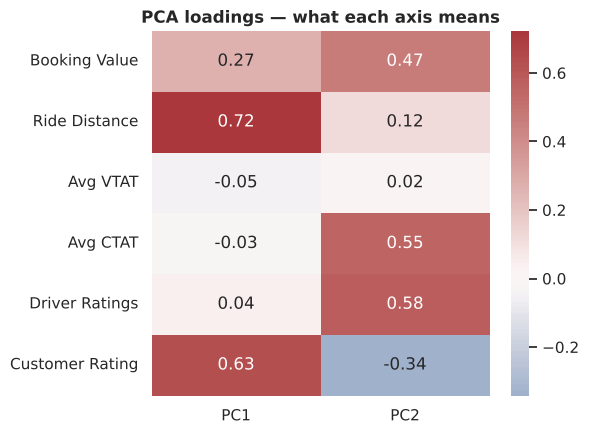

In [20]:
loadings = pd.DataFrame(pca.components_.T, index=FEATS, columns=['PC1', 'PC2'])
plt.figure(figsize=(6, 4.5)); sns.heatmap(loadings, annot=True, fmt='.2f', cmap='vlag', center=0)
plt.title('PCA loadings — what each axis means', fontweight='bold'); plt.tight_layout(); plt.show(); plt.close('all')

### E3. t-SNE projection (encouraged)

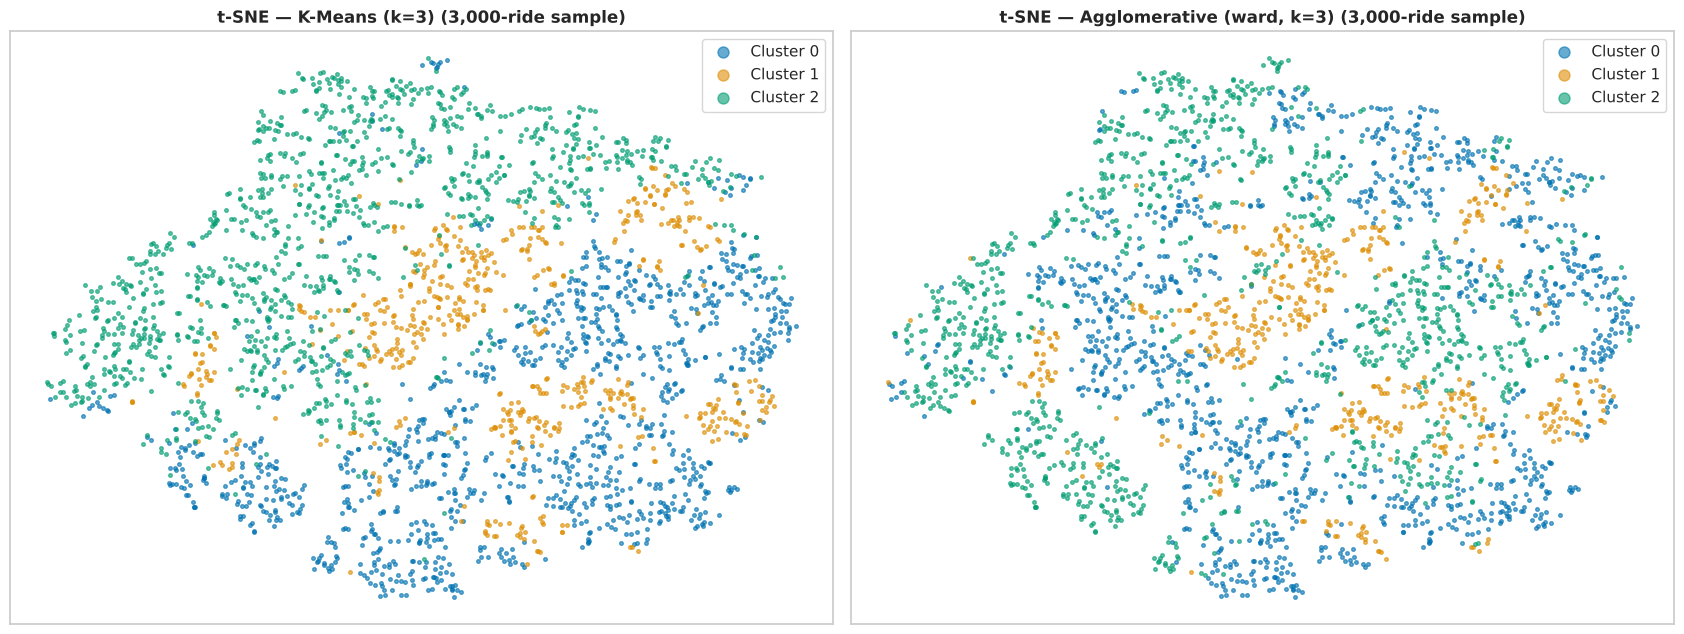

In [21]:
from sklearn.manifold import TSNE
ts_idx = np.random.RandomState(RANDOM_STATE).choice(len(X), 3000, replace=False)
T = TSNE(n_components=2, perplexity=40, init='pca', random_state=RANDOM_STATE).fit_transform(X[ts_idx])
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, (title, lab) in zip(axes, [(res_df.iloc[0]['Algorithm'], km_labels[ts_idx]), (res_df.iloc[1]['Algorithm'], agg_lab[ts_idx])]):
    for c in np.unique(lab):
        ax.scatter(T[lab == c, 0], T[lab == c, 1], s=7, alpha=.6, color=palette[c % 10], label=f'Cluster {c}')
    ax.set_title(f't-SNE — {title} (3,000-ride sample)', fontweight='bold'); ax.legend(markerscale=3); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show(); plt.close('all')

### E4. Cluster profiles — what each segment looks like

,Booking Value,Ride Distance,Avg VTAT,Avg CTAT,Driver Ratings,Customer Rating,Rides
Cluster,,,,,,,
0,504.28,25.46,8.59,22.43,4.39,4.43,4030
1,494.16,26.70,8.72,30.16,3.54,4.43,1971
2,512.17,26.57,8.39,37.94,4.40,4.37,3999


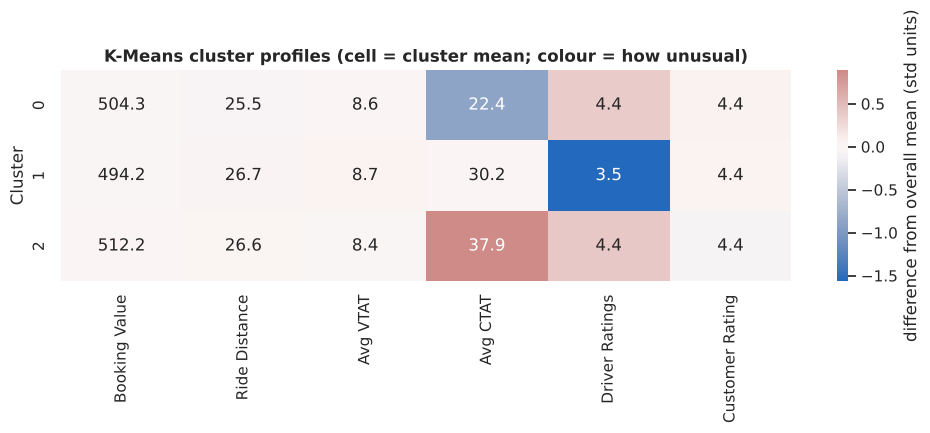

Cluster 0 (4,030 rides): Avg CTAT low (-0.89 sd), Driver Ratings high (+0.37 sd)
Cluster 1 (1,971 rides): Driver Ratings low (-1.57 sd), Avg VTAT high (+0.05 sd)
Cluster 2 (3,999 rides): Avg CTAT high (+0.89 sd), Driver Ratings high (+0.40 sd)


In [22]:
prof = raw.assign(Cluster=km_labels).groupby('Cluster')[NUM].mean()
prof['Rides'] = np.bincount(km_labels)
display(prof.round(2))
z = (prof[NUM] - raw[NUM].mean()) / raw[NUM].std()
plt.figure(figsize=(10, 0.7 * K + 2))
sns.heatmap(z, annot=prof[NUM].round(1), fmt='', cmap='vlag', center=0, cbar_kws={'label': 'difference from overall mean (std units)'})
plt.title('K-Means cluster profiles (cell = cluster mean; colour = how unusual)', fontweight='bold'); plt.tight_layout(); plt.show(); plt.close('all')
for c, row in z.iterrows():
    top = row.abs().sort_values(ascending=False).index[:2]
    print(f"Cluster {c} ({prof.loc[c, 'Rides']:,} rides): " + ", ".join(f"{f} {'high' if row[f] > 0 else 'low'} ({row[f]:+.2f} sd)" for f in top))

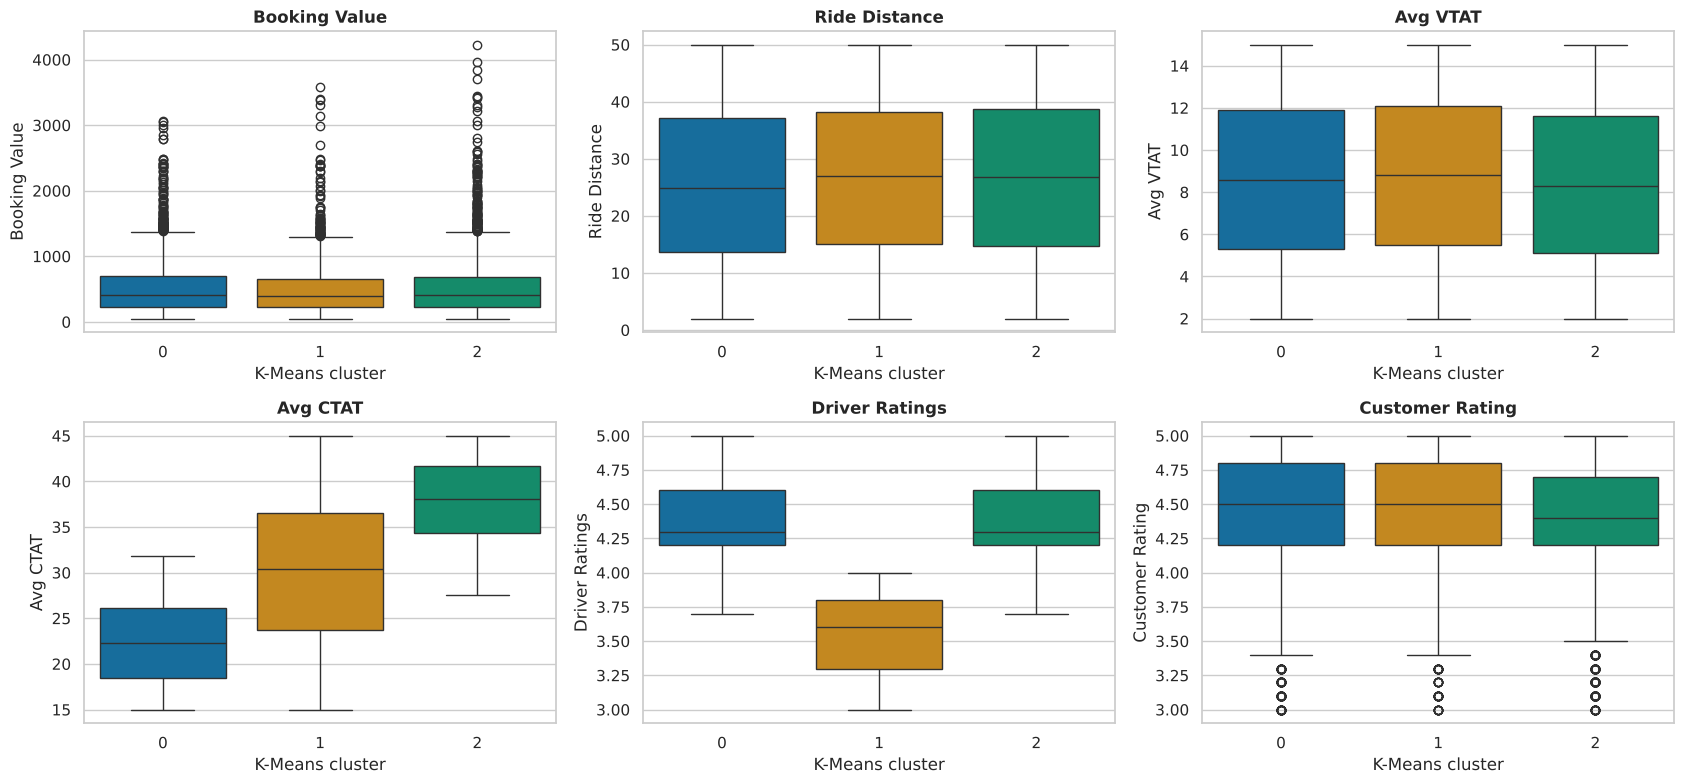

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, col in zip(axes.ravel(), NUM):
    sns.boxplot(x=km_labels, y=raw[col], palette=palette[:K], ax=ax); ax.set_title(col, fontweight='bold'); ax.set_xlabel('K-Means cluster')
plt.tight_layout(); plt.show(); plt.close('all')

## Section F — Post-hoc Interpretation & Conclusion

Only now do we bring back the label-like columns, to see whether the discovered segments correspond to known categories.

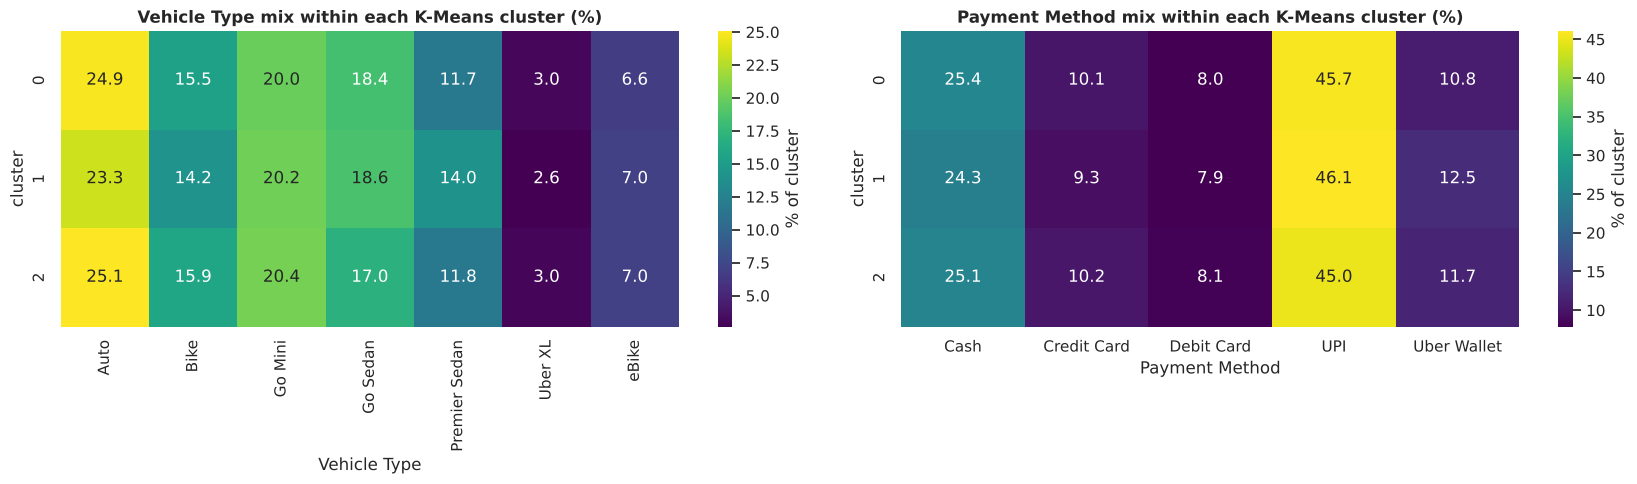

ARI(K-Means clusters, Vehicle Type) = 0.0006   (0 = no relation)
ARI(K-Means clusters, Payment Method) = -0.0005   (0 = no relation)


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for ax, col in zip(axes, ['Vehicle Type', 'Payment Method']):
    ct = pd.crosstab(km_labels, raw[col], normalize='index') * 100
    sns.heatmap(ct, annot=True, fmt='.1f', cmap='viridis', ax=ax, cbar_kws={'label': '% of cluster'})
    ax.set_title(f'{col} mix within each K-Means cluster (%)', fontweight='bold'); ax.set_ylabel('cluster')
plt.tight_layout(); plt.show(); plt.close('all')
for col in ['Vehicle Type', 'Payment Method']:
    print(f"ARI(K-Means clusters, {col}) = {adjusted_rand_score(raw[col], km_labels):.4f}   (0 = no relation)")

In [25]:
best = res_df.set_index('Algorithm').loc[best_algo]
print("CLUSTERING TRACK — SUMMARY")
print("=" * 60)
print(f"Rides clustered         : {len(X):,}  | features: {', '.join(FEATS)}")
print(f"K (elbow + silhouette)  : {K}")
print(f"Best Agglomerative link : {best_link}")
print(f"Selected algorithm      : {best_algo}")
print(f"  Silhouette {best['Silhouette']:.4f} | Davies-Bouldin {best['Davies-Bouldin']:.4f} | Calinski-Harabasz {best['Calinski-Harabasz']:.1f}")
print(f"Algorithm agreement ARI : {adjusted_rand_score(km_labels, agg_lab):.3f}")

CLUSTERING TRACK — SUMMARY
Rides clustered         : 10,000  | features: Booking Value, Ride Distance, Avg VTAT, Avg CTAT, Driver Ratings, Customer Rating
K (elbow + silhouette)  : 3
Best Agglomerative link : ward
Selected algorithm      : K-Means (k=3)
  Silhouette 0.1293 | Davies-Bouldin 2.2218 | Calinski-Harabasz 1309.5
Algorithm agreement ARI : 0.182


### Export — segmentation model and profiles (used by the web app)

In [26]:
import joblib, json
seg_model = Pipeline([('prep', prep), ('kmeans', kmeans)])          # prep was fitted above; kmeans fitted on prep output
assert (seg_model.predict(raw[NUM]) == km_labels).all()            # sanity check: identical labels
joblib.dump(seg_model, '../models/clustering_kmeans.joblib')
seg_meta = {'K': int(K), 'elbow_k': int(elbow_k), 'silhouette_k': int(sil_k), 'best_linkage': best_link, 'best_algorithm': best_algo,
            'features': NUM, 'pca_variance_2d': float(pca.explained_variance_ratio_.sum()),
            'ari_kmeans_vs_agglomerative': float(adjusted_rand_score(km_labels, agg_lab)),
            'profiles': prof.round(3).reset_index().to_dict(orient='records'),
            'feature_ranges': {c: [float(raw[c].min()), float(raw[c].median()), float(raw[c].max())] for c in NUM}}
json.dump(seg_meta, open('../models/clustering_meta.json', 'w'), indent=2)
k_df.round(4).to_csv('../models/clustering_k_search.csv', index=False)
link_df.round(4).to_csv('../models/clustering_linkage.csv', index=False)
pd.DataFrame({'PC1': P[:, 0], 'PC2': P[:, 1], 'kmeans': km_labels, 'agglomerative': agg_lab}).sample(3000, random_state=RANDOM_STATE).round(4).to_csv('../models/clustering_pca_sample.csv', index=False)
print("Saved clustering_kmeans.joblib, clustering_meta.json and helper CSVs to ../models/")

Saved clustering_kmeans.joblib, clustering_meta.json and helper CSVs to ../models/


**Conclusions**
- Both required algorithms were fitted on the same scaled feature matrix with the same *K*, and evaluated with all three mandatory metrics; the elbow curve, dendrograms, PCA plots for both algorithms and a t-SNE plot are shown above.
- The silhouette scores are **modest** (well below 0.5) and the elbow is gentle: the rides form a continuum rather than sharply separated groups, which is typical of operational data whose features are nearly uncorrelated. The clusters are therefore best read as *useful segments* (see the profile heatmap) rather than natural, distinct types.
- The post-hoc check shows whether the segments align with vehicle type or payment method; a near-zero ARI means the segments are driven by trip length, fare and service quality rather than by the service class.
- **Limitations & future work:** adding behavioural features (time of day, pickup zone, cancellation history) or density-based methods (DBSCAN/HDBSCAN) could reveal sharper structure.